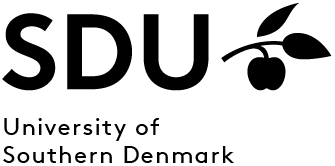
<br><br><br>
<p style="color: #789D4A;font-family: courier;font-size: 160%;text-align:center;">Optimization and Image Processing (E26)</p> 

<p style="color: #789D4A;font-family: courier;font-size: 120%;text-align:center;">Dr Till Leissner, Associate Professor</p> 
<p style="color: #789D4A;font-family: courier;font-size: 120%;text-align:center;">Mads Clausen Institute, University of Southern Denmark</p> 

## Hough transformation

In [1]:
import numpy as np
try:
    import oip
except Exception:
    oip = None

## Pair prediction (2 min)

If several edge points belong to the same image line, what common feature
should their voting curves have in parameter space?

**Vote:** can separated collinear fragments still produce one strong Hough
peak?

For the three-point example $(0,1)$, $(1,2)$ and $(2,3)$, derive the voting
curves $d=-x_i k+y_i$ before running the next cell.

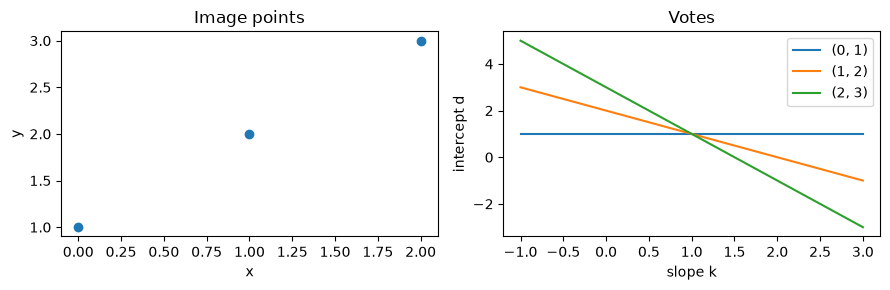

In [2]:
oip.week05.show_votes()

### Discuss after running
The votes are \(d=1\), \(d=2-k\), \(d=3-2k\). They meet at \((k,d)=(1,1)\), representing \(y=x+1\).

## Quick check

For a vertical image line, which direction does its normal point? Use this to
predict $\theta$ before checking the numerical example in the next cell.

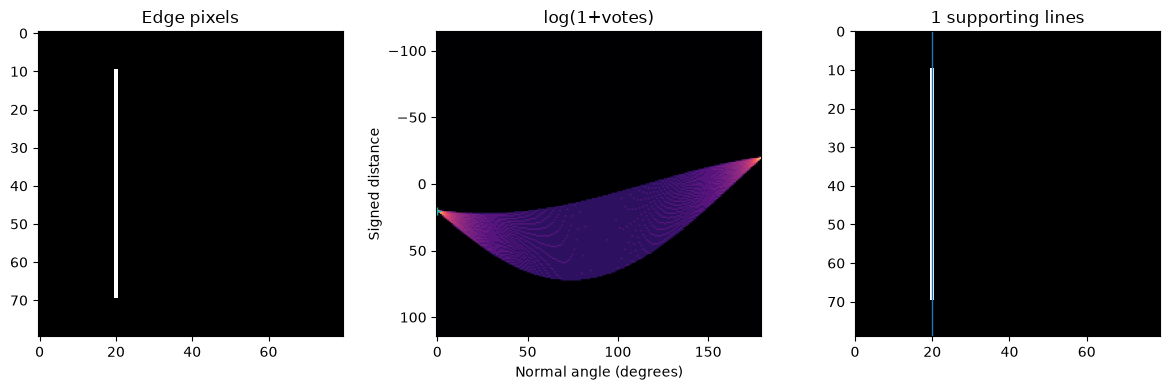

Normal angle: [0.] Signed distance: [20.]


In [3]:
from skimage.transform import hough_line, hough_line_peaks

vertical = np.zeros((80, 80), dtype=bool)
vertical[10:70, 20] = True
angles = np.deg2rad(np.arange(0, 180, 1))
accumulator, angles, distances = hough_line(vertical, theta=angles)
peaks = hough_line_peaks(accumulator, angles, distances, num_peaks=1)
oip.week05.show_hough(vertical, accumulator, angles, distances, peaks)
print("Normal angle:", np.rad2deg(peaks[1]), "Signed distance:", peaks[2])

### Discuss after running
\(\theta=0\), \(\rho=20\). The angle is the normal direction. We explicitly use \([0,\pi)\) to match the lecture slides; \(x\) is column and \(y\) is row.

## Activity — Think–Pair–Vote–Test–Share

1. **Pair:** derive the voting curves for the three-point example above.
2. **Predict:** do gaps in a line destroy its accumulator peak?
3. **Vote:** does a Hough peak determine the endpoints of a line segment?
4. **Test:** vary missing support and accumulator resolution below.
5. **Share:** identify one failure mode and where you think it originates.

Try the same pipeline on a photograph or your own image. If an LLM suggests a
parameter change, test the claim rather than treating it as an answer.

Reuse the three-line example from `l06.ipynb`. It is already an edge map; do not apply Canny to it. First run the baseline; then change `missing` to 0.5; then restore it and change `angle_step` to 5. Compare one parameter at a time.

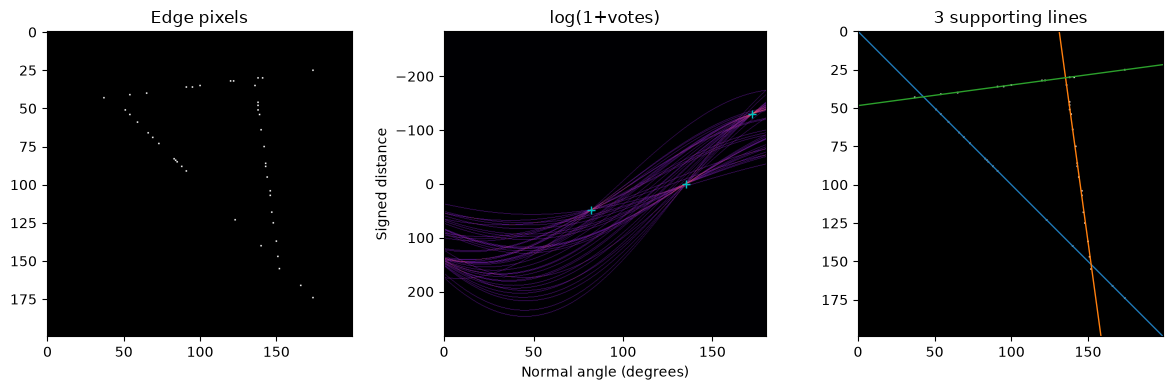

In [15]:
missing = 0.9
angle_step = 0.15 # try 5.0 (coarse) or 0.25 (fine)

edges = oip.week05.line_image(missing=missing)

# Lecture fill-in (about 1 min): sample theta over the lecture convention
# 0 <= theta < pi using angle_step in degrees.
angles = np.deg2rad(np.arange(0,180,angle_step))

accumulator, angles, distances = hough_line(edges, theta=angles)
peaks = hough_line_peaks(
    accumulator,
    angles,
    distances,
    threshold=0.4 * accumulator.max(),
    num_peaks=6,
    min_angle=max(1, round(5 / angle_step)),
)
oip.week05.show_hough(edges, accumulator, angles, distances, peaks)


### Interactive demo — missing support and angular resolution

Use the sliders to test how robust the Hough transform is to missing edge
pixels and how the discretization of angle space affects the accumulator.
Predict the result before changing either slider.

Separated fragments still vote for the same supporting line. Coarse angle bins limit precision and can merge nearby lines. Fine sampling uses more memory and can spread noisy evidence between nearby parameter cells; it is not automatically more reliable. Only angle resolution changes here; the library fixes the distance-bin spacing. Detected supporting lines have no endpoints. Peak separation is adjusted to approximately five degrees so it does not unintentionally change with angle resolution.

In [16]:
from ipywidgets import FloatSlider, interact

def hough_demo(missing=0.0, angle_step=1.0):
    demo_edges = oip.week05.line_image(missing=missing)
    theta = np.deg2rad(np.arange(0, 180, angle_step))

    demo_accumulator, demo_angles, demo_distances = hough_line(
        demo_edges,
        theta=theta,
    )
    demo_peaks = hough_line_peaks(
        demo_accumulator,
        demo_angles,
        demo_distances,
        threshold=0.4 * demo_accumulator.max(),
        num_peaks=6,
        min_angle=max(1, round(5 / angle_step)),
    )

    oip.week05.show_hough(
        demo_edges,
        demo_accumulator,
        demo_angles,
        demo_distances,
        demo_peaks,
    )

interact(
    hough_demo,
    missing=FloatSlider(
        value=0.0, min=0.0, max=0.8, step=0.1,
        description="missing",
    ),
    angle_step=FloatSlider(
        value=1.0, min=0.25, max=5.0, step=0.25,
        description="deg/bin",
    ),
);

interactive(children=(FloatSlider(value=0.0, description='missing', max=0.8), FloatSlider(value=1.0, descripti…

### Connect the Canny recap to Hough
Use the same bundled camera image. Expect many possible lines and imperfect results; discuss whether strong lines are actually the objects of interest.

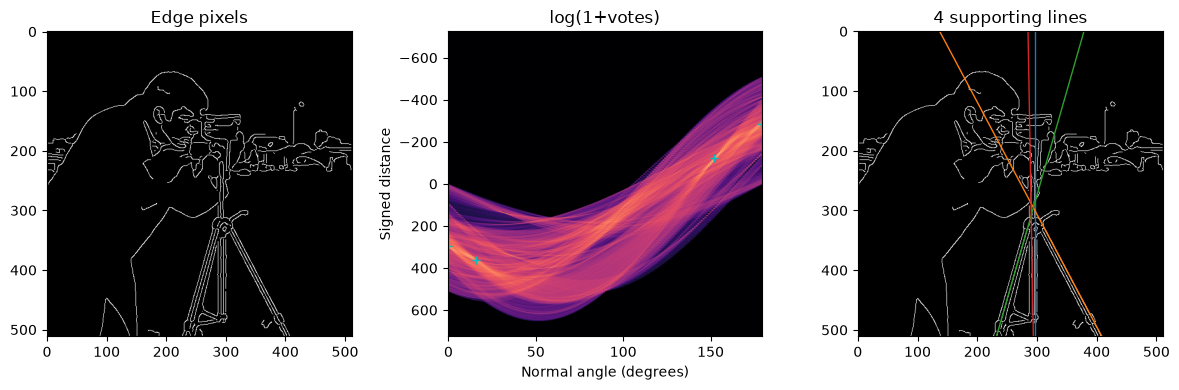

In [17]:
from skimage import data
from skimage.feature import canny
from skimage.util import img_as_float

photo = img_as_float(data.camera())
edges = canny(photo, sigma=2, low_threshold=0.1, high_threshold=0.2)
accumulator, angles, distances = hough_line(edges, theta=np.deg2rad(np.arange(180)))
peaks = hough_line_peaks(accumulator, angles, distances, num_peaks=6)
oip.week05.show_hough(edges, accumulator, angles, distances, peaks)

## Optional programming challenge

Interested in the actual implementation? Continue with
[`l05-6_optional_programming.ipynb`](l05-6_optional_programming.ipynb).
The optional notebook follows the Burger & Burge algorithm structure and keeps
the implementation-focused, scored exercises separate from the lecture demo.

## Assignment — detect lines that matter

Work in pairs or groups.

1. Choose an image containing at least two meaningful straight structures.
   Your own photograph or a laboratory/device image is encouraged.
2. Create an edge map and detect Hough peaks.
3. Change **one Canny parameter** and **one Hough parameter** separately.
4. Identify one useful line, one missed line, and one false or irrelevant line.
5. Explain whether each failure originates mainly from edge detection, Hough
   voting, discretization or peak selection.
6. If practical, compare with a FIJI Hough implementation/plugin.
7. Ask an LLM for one proposed fix for a failure case and test whether it
   actually improves the result.

**Submit:** input image, edge map, line overlay and a short evidence-based
discussion.

### Share something interesting on Itslearning

This week, **sharing examples and results is encouraged**. If your Hough
experiment produces something informative, post it to the Week 05 Itslearning
submission rather than keeping it to yourself.

Examples worth sharing:

- a broken or partly occluded line that is still detected;
- a strong accumulator peak that corresponds to an irrelevant line;
- a line that is obvious to you but is missed by the algorithm;
- a striking effect of angle/bin resolution on the detected peaks;
- an example showing that the Canny edge map, rather than Hough voting, causes
  the failure;
- a useful or misleading LLM suggestion for fixing a failure case;
- a Python/FIJI comparison on your own image.

A useful post can be **the input or edge image + line overlay/accumulator view +
the key parameters + a short explanation**. Interesting failures are just as
valuable as successful detections.
